In [23]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict, Literal


In [24]:
class ContentModerationInput(TypedDict):
    post_content:str
    user_reputation:str
    
    formated_post:str
    content_flag:str
    result:str
    

In [25]:
def format_post(state:ContentModerationInput):
    formated_post = f"{state['user_reputation']} says {state['post_content']}"
    return {'formated_post':formated_post}

In [26]:
def analyze_content(state:ContentModerationInput):
    content = state['post_content'].lower()

    # Simple mock logic for content moderation
    if 'spam' in content or 'buy now' in content:
        flag = 'rejected'
    elif state['user_reputation'] == 'new_user':
        flag = 'review'
    else:
        flag = 'approved'

    return {'content_flag': flag}

In [27]:
def approve_post(state:ContentModerationInput):
    return {'result': 'Post approved and published.'}

In [28]:
def flag_post(state:ContentModerationInput):
    return {'result': 'Post flagged for review.'}

In [29]:
def reject_post(state:ContentModerationInput):
    return {'result': 'Post rejected due to content policy violation.'}

In [30]:
graph = StateGraph(ContentModerationInput)

graph.add_node('format_post',format_post)
graph.add_node('analyze_content',analyze_content)
graph.add_node('approve_post',approve_post)
graph.add_node('flag_post',flag_post)
graph.add_node('reject_post',reject_post)

In [31]:
def check_condition(state:ContentModerationInput) -> Literal['approve_post','flag_post','reject_post']:
    if state['content_flag'] == 'approved':
        return 'approve_post'
    elif state['content_flag'] == 'review':
        return 'flag_post'
    else:
        return 'reject_post'

In [32]:
#add edges
graph.add_edge(START,'format_post')
graph.add_edge('format_post','analyze_content')

graph.add_conditional_edges('analyze_content',check_condition)
graph.add_edge('approve_post',END)
graph.add_edge('flag_post',END)
graph.add_edge('reject_post',END)


In [33]:
def check_condition(state:ContentModerationInput) -> Literal['approve_post','flag_post','reject_post']:
    if state['content_flag'] == 'approved':
        return 'approve_post'
    elif state['content_flag'] == 'review':
        return 'flag_post'
    else:
        return 'reject_post'

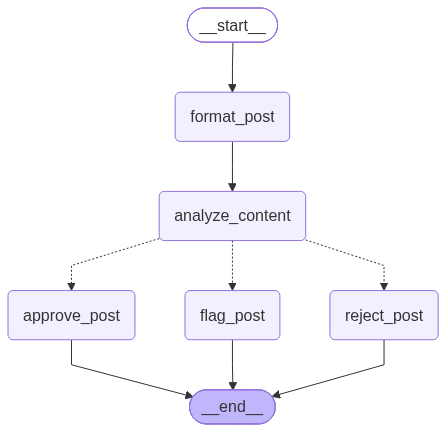

In [34]:
workflow=graph.compile()
workflow

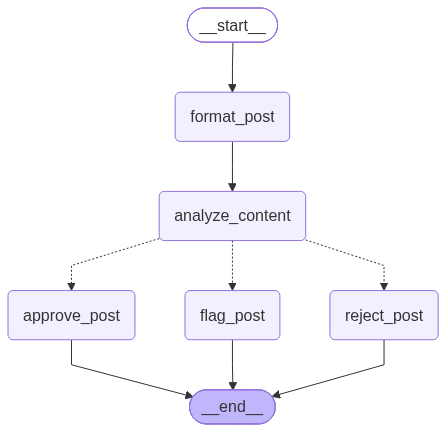

In [35]:
workflow

In [44]:
intial_state={
    'post_content':"This is a test post. now!",
    'user_reputation':"new_user"
}


In [45]:
result = workflow.invoke(intial_state)
result

{'post_content': 'This is a test post. now!',
 'user_reputation': 'new_user',
 'formated_post': 'new_user says This is a test post. now!',
 'content_flag': 'review',
 'result': 'Post flagged for review.'}